In [ ]:
import marimo as mo

# Cuando llueve en Hermosillo: la historia para el 911

El notebook 08 estableció que la lluvia dispara las llamadas al 911 por inundación y
terreno. Este notebook traduce ese hallazgo a lo que el servicio del 911 puede esperar
un día de lluvia, y produce una gráfica por cada parte de la historia para el reporte
(`docs/reporte/reporte.tex`). Las figuras se guardan en `docs/img/historia/`.

Arco de la historia:

1. Una ciudad donde casi no llueve, salvo en el verano.
2. El día que llueve, las llamadas se multiplican según cuánto llueve.
3. La presión dura dos días.
4. Qué se reporta: árboles, inundaciones y hundimientos.
5. A qué hora: la noche y la madrugada.
6. Dónde: un grupo de colonias que se repite cada temporada.
7. Lo que la lluvia no explica: baches y agua potable.

Llamadas consideradas: los 28 tipos del filtro del 911 menos los 4 de ahogamientos (24 tipos) (que no
dependen de la lluvia en la ciudad), de enero de 2018 a septiembre de 2025.

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project_name import water_events as we
from project_name.config import PROJECT_ROOT
from project_name.eda import CATEGORICAL, NEUTRAL

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
FIGURES = PROJECT_ROOT / "docs" / "img" / "historia"
FIGURES.mkdir(parents=True, exist_ok=True)

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8, colors=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    return fig

In [ ]:
rain = we.load_rain()
colonias = we.load_colonias()
calls = we.rain_related_calls(we.load_calls(colonias))

## 1. Una ciudad donde casi no llueve, salvo en el verano

In [ ]:
_window = slice("2018-01-01", "2025-09-30")
monthly = pd.DataFrame(
    {
        "lluvia_mm": rain[_window].resample("MS").sum(),
        "llamadas": calls.set_index("date").resample("MS").size(),
    }
).fillna(0)
_rain = rain[_window]
rain_days = pd.DataFrame(
    {
        "días con 10 mm o más": (_rain >= 10).groupby(_rain.index.year).sum(),
        "lluvia anual mm": _rain.groupby(_rain.index.year).sum().round(0),
    }
)
_summer = monthly.index.month.isin([7, 8, 9])
summer_share = pd.Series(
    {
        "% de la lluvia en julio a septiembre": round(
            100 * monthly.loc[_summer, "lluvia_mm"].sum() / monthly["lluvia_mm"].sum(), 1
        ),
        "% de las llamadas en julio a septiembre": round(
            100 * monthly.loc[_summer, "llamadas"].sum() / monthly["llamadas"].sum(), 1
        ),
        "días con 10 mm o más por año (promedio 2018 a 2024)": round(
            rain_days.loc[2018:2024, "días con 10 mm o más"].mean(), 1
        ),
        "días con 10 mm o más, 2018 a septiembre de 2025": int((_rain >= 10).sum()),
        "de ellos en julio a septiembre": int(
            ((_rain >= 10) & _rain.index.month.isin([7, 8, 9])).sum()
        ),
    }
)
rain_days, summer_share

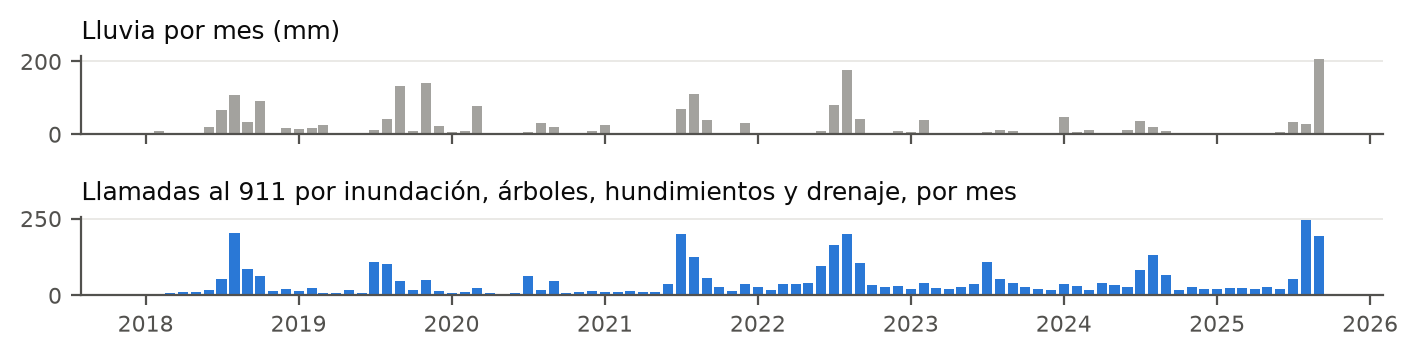

In [ ]:
_fig, (_top, _bottom) = plt.subplots(2, 1, figsize=(7.2, 1.9), sharex=True)
_width = pd.Timedelta(days=24)
_top.bar(monthly.index, monthly["lluvia_mm"], width=_width, color=NEUTRAL)
_bottom.bar(monthly.index, monthly["llamadas"], width=_width, color=CATEGORICAL[0])
_top.set_title("Lluvia por mes (mm)", loc="left", fontsize=9)
_bottom.set_title(
    "Llamadas al 911 por inundación, árboles, hundimientos y drenaje, por mes",
    loc="left",
    fontsize=9,
)
for _ax in (_top, _bottom):
    style(_ax)
_fig.tight_layout()
save(_fig, "1_calendario")

## 2. El día que llueve, las llamadas se multiplican según cuánto llueve

Llamadas del mismo día en la temporada (junio a octubre), según la lluvia de ese día. El
"día malo" es el que solo superan 1 de cada 10 días de esa categoría.

In [ ]:
intensity = we.calls_by_intensity(rain, calls).round(1)
intensity

,dias,promedio,dia_malo,maximo
intensidad,,,,
seco (<1 mm),1001,1.7,4.0,47
1 a 10 mm,155,5.1,11.0,47
10 a 20 mm,21,9.0,18.0,61
20 a 40 mm,10,16.8,50.7,66
40 mm o más,6,18.7,42.5,46


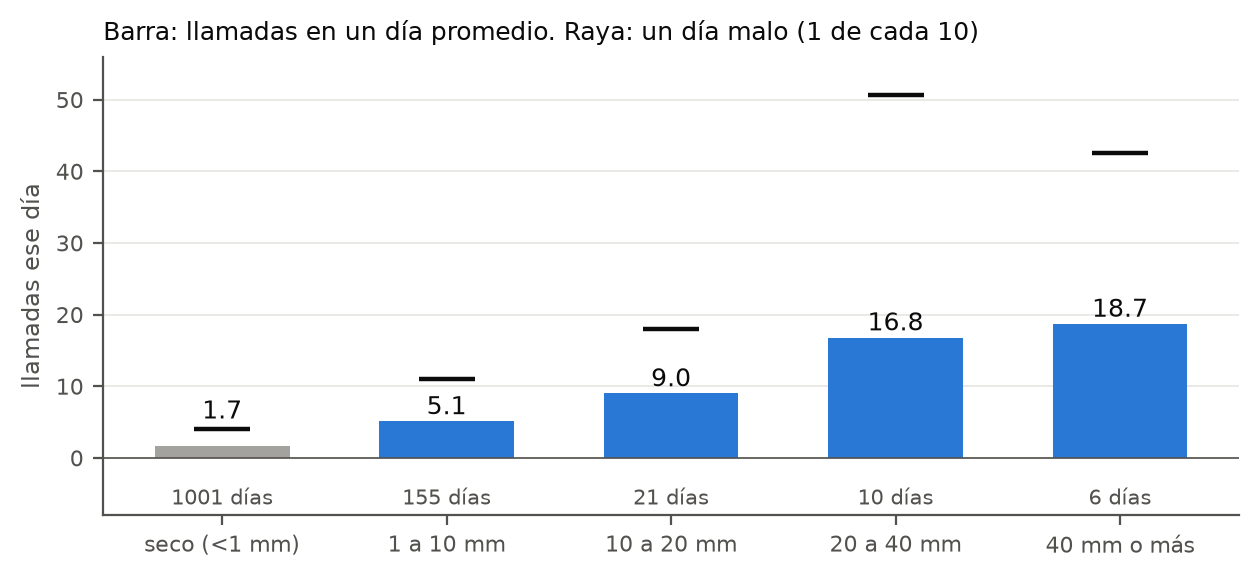

In [ ]:
_fig, _ax = plt.subplots(figsize=(6.4, 3.0))
_x = range(len(intensity))
_colors = [NEUTRAL] + [CATEGORICAL[0]] * (len(intensity) - 1)
_ax.bar(_x, intensity["promedio"], color=_colors, width=0.6)
_ax.scatter(_x, intensity["dia_malo"], marker="_", s=420, color=INK, lw=1.6, zorder=3)
for _i, (_mean, _bad, _days) in enumerate(
    zip(intensity["promedio"], intensity["dia_malo"], intensity["dias"])
):
    # Si la raya del día malo queda pegada a la barra, la cifra va arriba de la raya.
    _label_y = _bad + 1.5 if _bad - _mean < 4 else _mean + 1
    _ax.text(_i, _label_y, f"{_mean:.1f}", ha="center", fontsize=9, color=INK)
    _ax.text(_i, -6.5, f"{_days} días", ha="center", fontsize=7.5, color=MUTED)
_ax.set_xticks(list(_x), intensity.index.astype(str), fontsize=8.5)
_ax.set_ylim(-8, 56)
_ax.set_ylabel("llamadas ese día", fontsize=8.5, color=MUTED)
_ax.set_title(
    "Barra: llamadas en un día promedio. Raya: un día malo (1 de cada 10)",
    loc="left",
    fontsize=9,
    color=INK,
)
_ax.axhline(0, color=MUTED, lw=0.6)
style(_ax)
_fig.tight_layout()
save(_fig, "2_intensidad")

## 3. La presión dura dos días

Llamadas promedio en los días alrededor de una lluvia de 20 mm o más que no venía
precedida de otra lluvia fuerte en los 3 días anteriores. Estas lluvias caen en
cualquier mes (7 de las 13 fuera de junio a octubre), así que la referencia es un día
seco de todo el año. Con solo las 6 de temporada la curva es demasiado ruidosa para
leer una duración.

In [ ]:
curve = we.event_curve(rain, calls)
# Como diccionario para que la salida guardada no se trunque.
(
    curve.set_index("dia")["llamadas"].round(2).to_dict(),
    curve.iloc[0][["eventos", "eventos_en_temporada", "dia_seco"]].round(2).to_dict(),
)

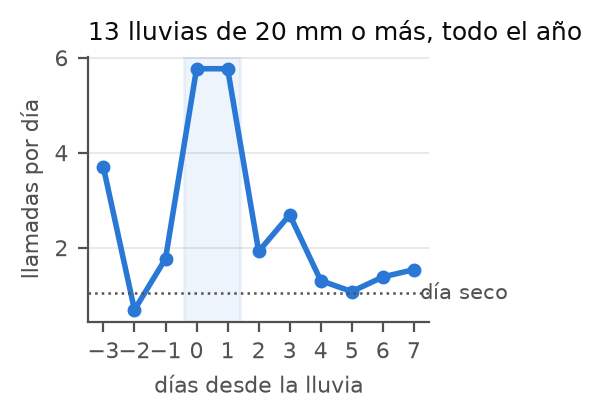

In [ ]:
_fig, _ax = plt.subplots(figsize=(2.7, 2.2))
_ax.plot(curve["dia"], curve["llamadas"], color=CATEGORICAL[0], lw=2, marker="o", ms=4)
_ax.axhline(curve["dia_seco"].iloc[0], color=MUTED, lw=0.9, ls=":")
_ax.text(7.2, curve["dia_seco"].iloc[0], "día seco", fontsize=7.5, color=MUTED, va="center")
_ax.axvspan(-0.4, 1.4, color=CATEGORICAL[0], alpha=0.08)
_ax.set_xticks(list(curve["dia"]))
_ax.set_xlabel("días desde la lluvia", fontsize=8, color=MUTED)
_ax.set_ylabel("llamadas por día", fontsize=8, color=MUTED)
_ax.set_title(
    f"{curve['eventos'].iloc[0]} lluvias de 20 mm o más, todo el año",
    loc="left",
    fontsize=9,
    color=INK,
)
style(_ax)
_fig.tight_layout()
save(_fig, "3_dos_dias")

## 4. Qué se reporta

Llamadas por día de cada tipo en los 8 días que siguen a una lluvia de 10 mm o más,
contra los días secos de la temporada. La diferencia es la carga extra que trae la lluvia.

In [ ]:
by_type = we.extra_calls_by_type(rain, calls).round(2)
by_type.head(10)

,tras lluvia,días secos,extra por día
tipo_incidente,,,
INUNDACIONES,1.30,0.06,1.24
ARBOL CAÍDO O POR CAER,1.92,0.70,1.23
HUNDIMIENTOS / AGRIETAMIENTOS/ INESTABILIDAD DE LADERA,0.54,0.07,0.47
ALCANTARILLA SIN TAPA,0.60,0.29,0.31
DERRUMBES,0.29,0.02,0.27
VIALIDAD EN MAL ESTADO,0.28,0.07,0.21
ENCHARCAMIENTO/ DESBORDAMIENTO DE RÍO,0.10,0.00,0.10
SOCAVÓN,0.10,0.00,0.10
FUGA DE AGUA POTABLE,0.05,0.00,0.05


In [ ]:
# Nombres cortos para la gráfica (las variantes ortográficas ya vienen unificadas).
_short = {
    "ARBOL CAÍDO O POR CAER": "árbol caído",
    "INUNDACIONES": "inundación",
    "ENCHARCAMIENTO/ DESBORDAMIENTO DE RÍO": "encharcamiento",
    "HUNDIMIENTOS / AGRIETAMIENTOS/ INESTABILIDAD DE LADERA": "hundimiento",
    "DERRUMBES": "derrumbe",
    "ALCANTARILLA SIN TAPA": "alcantarilla sin tapa",
    "VIALIDAD EN MAL ESTADO": "calle en mal estado",
    "SOCAVÓN": "socavón",
}
_grouped = (
    by_type.rename(index=lambda _name: _short.get(_name, "otros"))
    .groupby(level=0)[["tras lluvia", "días secos"]]
    .sum()
)
_grouped["extra"] = _grouped["tras lluvia"] - _grouped["días secos"]
type_chart = _grouped.drop(index="otros").sort_values("extra")
_fig, _ax = plt.subplots(figsize=(2.9, 2.2))
_y = range(len(type_chart))
_ax.barh(_y, type_chart["días secos"], color="#c9c8c4", height=0.6, label="día seco")
_ax.barh(
    _y,
    type_chart["extra"],
    left=type_chart["días secos"],
    color=CATEGORICAL[0],
    height=0.6,
    label="extra tras lluvia",
)
for _i, _total in enumerate(type_chart["tras lluvia"]):
    _ax.text(_total + 0.04, _i, f"{_total:.1f}", va="center", fontsize=7.5, color=INK)
_ax.set_yticks(list(_y), type_chart.index, fontsize=8)
_ax.set_xlabel("llamadas por día", fontsize=8, color=MUTED)
_ax.legend(fontsize=7, frameon=False, loc="lower center", bbox_to_anchor=(0.4, 1.0), ncol=2)
style(_ax)
_ax.grid(axis="y", visible=False)
_ax.grid(axis="x", color="#e6e5e1", lw=0.6)
_fig.tight_layout()
save(_fig, "4_tipos")
pd.DataFrame(type_chart).round(2)

,tras lluvia,días secos,extra
tipo_incidente,,,
encharcamiento,0.10,0.00,0.10
socavón,0.10,0.00,0.10
calle en mal estado,0.28,0.07,0.21
derrumbe,0.29,0.02,0.27
alcantarilla sin tapa,0.60,0.29,0.31
hundimiento,0.54,0.07,0.47
árbol caído,1.92,0.70,1.22
inundación,1.30,0.06,1.24


## 5. A qué hora

Reparto de las llamadas por hora en los días con 10 mm o más de lluvia, contra los días
secos.

In [ ]:
hours = we.hour_profile(rain, calls)
night = hours.loc[1:5].sum().round(1).rename("% entre 1:00 y 5:59")
hour_counts = {
    "llamadas en días con 10 mm o más": int((calls["date"].map(rain) >= 10).sum()),
    "llamadas en días secos": int(
        (calls["date"].map(we.response_window(rain)) < we.DRY_MM).sum()
    ),
}
hours.round(1).to_dict(), night, hour_counts

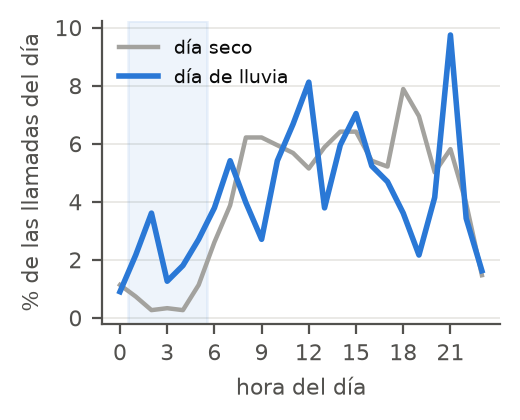

In [ ]:
_fig, _ax = plt.subplots(figsize=(2.7, 2.2))
_ax.plot(hours.index, hours["día seco"], color=NEUTRAL, lw=1.6, label="día seco")
_ax.plot(
    hours.index, hours["día de lluvia"], color=CATEGORICAL[0], lw=2, label="día de lluvia"
)
_ax.axvspan(0.5, 5.5, color=CATEGORICAL[0], alpha=0.08)
_ax.set_xticks([0, 3, 6, 9, 12, 15, 18, 21])
_ax.set_xlabel("hora del día", fontsize=8, color=MUTED)
_ax.set_ylabel("% de las llamadas del día", fontsize=8, color=MUTED)
_ax.legend(fontsize=7, frameon=False)
style(_ax)
_fig.tight_layout()
save(_fig, "5_horas")

## 6. Dónde

Colonias de la ciudad según en cuántos años calendario tuvieron llamadas en los 8 días
posteriores a una lluvia de 10 mm o más. Solo cuenta el 80.4% de las llamadas que se
ubican en una colonia (catálogo del INEGI más equivalencias revisadas a mano).

In [ ]:
seasons = we.seasons_with_calls(rain, calls)
core = seasons[seasons["temporadas"] >= 3]
core_summary = {
    "colonias con alguna llamada tras lluvia": len(seasons),
    "colonias en 3 años o más": len(core),
    "% de las llamadas ubicadas tras lluvia en esas colonias": round(
        100 * core["llamadas"].sum() / seasons["llamadas"].sum(), 1
    ),
    "área mediana de esas colonias (km²)": round(
        colonias.set_index("colonia_id").loc[core.index, "area_km2"].median(), 2
    ),
    "área mediana de todas las colonias (km²)": round(colonias["area_km2"].median(), 2),
}
core_list = (
    core.join(colonias.set_index("colonia_id")["settlement_name"])
    .sort_values(["llamadas", "temporadas"], ascending=False)
    .head(15)
)
core_summary, core_list.to_dict(orient="index")

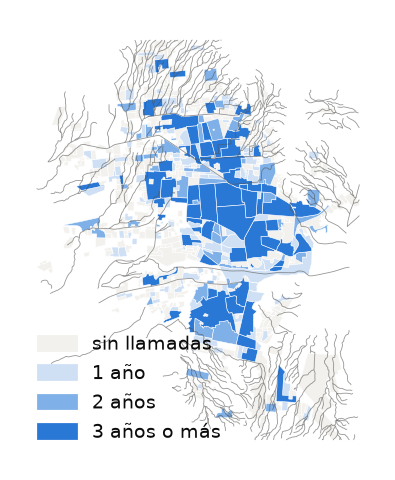

In [ ]:
_city = colonias.merge(seasons, left_on="colonia_id", right_index=True, how="left").fillna(
    {"temporadas": 0}
)
_city = _city.to_crs(we.METRIC_CRS)
_streams = gpd.read_file(we.SUBCUENCAS_FILE, layer="hl").to_crs(we.METRIC_CRS)
_streams = _streams[_streams.intersects(_city.union_all().buffer(500))]
_classes = [
    (0, 0, "#f2f1ee", "sin llamadas"),
    (1, 1, "#cfe0f5", "1 año"),
    (2, 2, "#7fb0e8", "2 años"),
    (3, 99, CATEGORICAL[0], "3 años o más"),
]
# Tamaño chico a propósito: en el reporte ocupa un tercio del ancho y así la leyenda
# no se encoge de más.
_fig, _ax = plt.subplots(figsize=(2.2, 2.5))
for _low, _high, _color, _label in _classes:
    _subset = _city[_city["temporadas"].between(_low, _high)]
    _subset.plot(ax=_ax, color=_color, edgecolor="white", linewidth=0.2, label=_label)
_streams.clip(_city.total_bounds).plot(ax=_ax, color="#52514e", linewidth=0.3, alpha=0.6)
_handles = [plt.Rectangle((0, 0), 1, 1, color=_c) for _, _, _c, _ in _classes]
_ax.legend(_handles, [_l for *_, _l in _classes], fontsize=7, frameon=False, loc="lower left")
_ax.set_axis_off()
_fig.tight_layout()
save(_fig, "6_colonias")

## 7. Lo que la lluvia no explica

Veces que sube cada serie en los 8 días que siguen a una lluvia de 10 mm o más, contra
días secos del mismo mes (control dentro del mismo mes de cada año, como en el notebook
08). En inundación muchos meses secos tienen cero llamadas; se usa la comparación de toda
la temporada.

In [ ]:
_calls = we.load_calls()
_series = {
    "911 inundación": we.daily_counts(
        _calls[_calls["grupo_incidente"] == "inundacion_directa"], "911"
    ),
    "911 terreno": we.daily_counts(_calls[_calls["grupo_incidente"] == "terreno"], "911"),
    "911 drenaje": we.daily_counts(
        _calls[_calls["grupo_incidente"] == "drenaje_y_red_de_agua"], "911"
    ),
    "baches atendidos": we.daily_counts(we.load_baches(), "baches"),
    "emergencias Agua de Hermosillo": we.daily_counts(
        (_posts := we.load_posts())[_posts["event_type"] == "emergencia"], "aguah"
    ),
}
_daily = we.daily_table(rain, _series)

def _within(_name):
    _m = we.within_month_ratio(_daily, _name)
    return _m["húmedo"].mean() / _m["seco"].mean()

not_rain = pd.DataFrame(
    {
        "temporada": {_n: we.event_study(_daily, _n)["razón"] for _n in _series},
        "mismo mes": {_n: _within(_n) for _n in ["911 terreno", "911 drenaje", "baches atendidos"]},
    }
).round(2)
not_rain

,temporada,mismo mes
911 inundación,21.70,NaN
911 terreno,3.66,1.52
911 drenaje,2.47,1.52
baches atendidos,1.42,0.97
emergencias Agua de Hermosillo,0.99,NaN


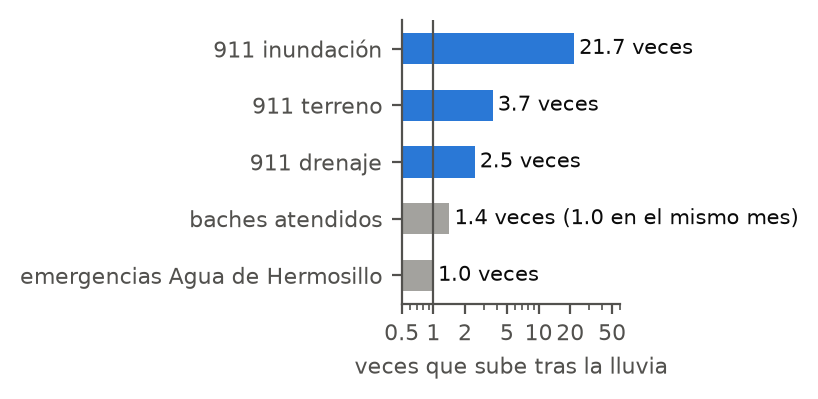

In [ ]:
# Misma comparación para todas las series (toda la temporada); en baches se anota el
# control dentro del mismo mes, que borra su aumento aparente.
_order = not_rain.sort_values("temporada")
_fig, _ax = plt.subplots(figsize=(3.4, 2.1))
_colors = [CATEGORICAL[0] if _n.startswith("911") else NEUTRAL for _n in _order.index]
_ax.barh(_order.index, _order["temporada"], color=_colors, height=0.55)
_ax.axvline(1, color=MUTED, lw=0.8)
_ax.set_xscale("log")
_ax.set_xlim(0.5, 60)
_ax.set_xticks([0.5, 1, 2, 5, 10, 20, 50], ["0.5", "1", "2", "5", "10", "20", "50"])
for _i, (_name, _value) in enumerate(_order["temporada"].items()):
    _label = f"{_value:.1f} veces"
    if _name == "baches atendidos":
        _label += f" ({_order.loc[_name, 'mismo mes']:.1f} en el mismo mes)"
    _ax.text(_value * 1.12, _i, _label, va="center", fontsize=7.5, color=INK)
_ax.tick_params(labelsize=8, colors=MUTED)
_ax.spines[["top", "right"]].set_visible(False)
_ax.set_xlabel("veces que sube tras la lluvia", fontsize=8, color=MUTED)
_fig.tight_layout()
save(_fig, "7_no_lluvia")